In [1]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
IMG_SIZE = (256, 256)
BATCH = 32

tf.keras.utils.set_random_seed(SEED)

SOURCE = "/kaggle/input/paddy-disease-classification/train_images"
TRAIN = "/kaggle/working/train"
VAL   = "/kaggle/working/val"

# ------------------------------------
# 1. Train/Validation Split (80/20)
# ------------------------------------
from sklearn.model_selection import train_test_split
import shutil

os.makedirs(TRAIN, exist_ok=True)
os.makedirs(VAL, exist_ok=True)

for cls in os.listdir(SOURCE):
    cls_path = os.path.join(SOURCE, cls)
    if not os.path.isdir(cls_path): continue

    files = os.listdir(cls_path)
    train_f, val_f = train_test_split(files, test_size=0.2, random_state=SEED)

    os.makedirs(os.path.join(TRAIN, cls), exist_ok=True)
    os.makedirs(os.path.join(VAL, cls), exist_ok=True)

    for f in train_f:
        shutil.copy(os.path.join(cls_path, f), os.path.join(TRAIN, cls, f))
    for f in val_f:
        shutil.copy(os.path.join(cls_path, f), os.path.join(VAL, cls, f))

print("Split done.")

# ------------------------------------
# 2. Image Generators
# ------------------------------------
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=25,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)


val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    TRAIN,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)


val_ds = val_gen.flow_from_directory(
    "/kaggle/working/val",
    target_size=(256,256),
    class_mode="categorical",
    shuffle=False,
    batch_size=32
)

print("Validation samples:", val_ds.samples)
print("Classes:", val_ds.class_indices)

NUM_CLASSES = len(train_ds.class_indices)

# ------------------------------------
# 3. DenseNet121 Model
# ------------------------------------
base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(256, 256, 3)
)
base.trainable = False   # freeze base for stability in JEI setting

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=Adam(1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------
# 4. Train Model
# ------------------------------------
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop],
    verbose=2
)




2026-08-09 05:34:15.407513: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1786253655.663269      40 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1786253655.728719      40 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Split done.
Found 8323 images belonging to 10 classes.
Found 2084 images belonging to 10 classes.
Validation samples: 2084
Classes: {'bacterial_leaf_blight': 0, 'bacterial_leaf_streak': 1, 'bacterial_panicle_blight': 2, 'blast': 3, 'brown_spot': 4, 'dead_heart': 5, 'downy_mildew': 6, 'hispa': 7, 'normal': 8, 'tungro': 9}


I0000 00:00:1786253717.184098      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786253717.186759      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15


I0000 00:00:1786253742.266239     116 service.cc:148] XLA service 0x7e808c002220 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1786253742.267458     116 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1786253742.267478     116 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1786253745.094678     116 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1786253756.388543     116 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


261/261 - 210s - 804ms/step - accuracy: 0.3505 - loss: 1.9915 - val_accuracy: 0.4702 - val_loss: 1.6464
Epoch 2/15
261/261 - 150s - 574ms/step - accuracy: 0.5299 - loss: 1.4297 - val_accuracy: 0.5782 - val_loss: 1.3002
Epoch 3/15
261/261 - 153s - 584ms/step - accuracy: 0.5943 - loss: 1.2260 - val_accuracy: 0.6440 - val_loss: 1.1285
Epoch 4/15
261/261 - 150s - 573ms/step - accuracy: 0.6358 - loss: 1.1050 - val_accuracy: 0.6742 - val_loss: 1.0168
Epoch 5/15
261/261 - 148s - 566ms/step - accuracy: 0.6737 - loss: 0.9970 - val_accuracy: 0.6982 - val_loss: 0.9453
Epoch 6/15
261/261 - 151s - 579ms/step - accuracy: 0.6977 - loss: 0.9371 - val_accuracy: 0.7078 - val_loss: 0.9185
Epoch 7/15
261/261 - 149s - 573ms/step - accuracy: 0.7151 - loss: 0.8868 - val_accuracy: 0.7202 - val_loss: 0.8755
Epoch 8/15
261/261 - 150s - 573ms/step - accuracy: 0.7223 - loss: 0.8418 - val_accuracy: 0.7289 - val_loss: 0.8490
Epoch 9/15
261/261 - 148s - 566ms/step - accuracy: 0.7438 - loss: 0.7881 - val_accuracy: 0.

In [2]:
path = "/kaggle/working/val"
import os, os.path
files = os.listdir(path)
for f in files: 
    subpath = path+"/"+f
    subfiles = os.listdir(subpath)
    percentage = ((len(subfiles))/2084.0)*100
    print(f+": "+str(len(subfiles))+", "+str(percentage))
    

bacterial_leaf_streak: 76, 3.6468330134357005
dead_heart: 289, 13.867562380038386
tungro: 218, 10.460652591170826
normal: 353, 16.93857965451056
hispa: 319, 15.307101727447217
brown_spot: 193, 9.261036468330134
downy_mildew: 124, 5.950095969289827
bacterial_panicle_blight: 68, 3.262955854126679
blast: 348, 16.698656429942417
bacterial_leaf_blight: 96, 4.606525911708253


In [3]:
# ==================================================
# Fine-tune DenseNet
# ==================================================

base.trainable = True

# Freeze everything except the last DenseNet block
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=2
)

Epoch 1/5
261/261 - 209s - 800ms/step - accuracy: 0.7835 - loss: 0.6794 - val_accuracy: 0.7745 - val_loss: 0.6928
Epoch 2/5
261/261 - 148s - 566ms/step - accuracy: 0.7902 - loss: 0.6655 - val_accuracy: 0.7764 - val_loss: 0.6951
Epoch 3/5
261/261 - 150s - 575ms/step - accuracy: 0.7973 - loss: 0.6333 - val_accuracy: 0.7788 - val_loss: 0.6966
Epoch 4/5
261/261 - 148s - 569ms/step - accuracy: 0.8034 - loss: 0.6200 - val_accuracy: 0.7802 - val_loss: 0.6820
Epoch 5/5
261/261 - 148s - 569ms/step - accuracy: 0.8109 - loss: 0.6027 - val_accuracy: 0.7841 - val_loss: 0.6703


In [4]:
model.save("/kaggle/working/densenet_bio_tool.h5")
print("Model saved.")

Model saved.


In [5]:
import pandas as pd

meta = pd.read_csv(
    "/kaggle/input/paddy-disease-classification/train.csv"
)

print(meta.head())
print(meta.columns)
print("Rows:", len(meta))

     image_id                  label variety  age
0  100330.jpg  bacterial_leaf_blight   ADT45   45
1  100365.jpg  bacterial_leaf_blight   ADT45   45
2  100382.jpg  bacterial_leaf_blight   ADT45   45
3  100632.jpg  bacterial_leaf_blight   ADT45   45
4  101918.jpg  bacterial_leaf_blight   ADT45   45
Index(['image_id', 'label', 'variety', 'age'], dtype='object')
Rows: 10407


In [6]:
import os

print("H5 / Keras model files:")

for root, dirs, files in os.walk("/kaggle"):
    for file in files:
        if file.endswith((".h5", ".hdf5", ".keras")):
            print(os.path.join(root, file))

H5 / Keras model files:
/kaggle/working/densenet_bio_tool.h5


In [7]:
print("Files in /kaggle/working:")
print(os.listdir("/kaggle/working"))

Files in /kaggle/working:
['val', 'densenet_bio_tool.h5', '.virtual_documents', 'train']


In [8]:
print("Is model already in memory?", "model" in globals())

if "model" in globals():
    print(model)
else:
    print("No model variable found.")

Is model already in memory? True
<Sequential name=sequential, built=True>


In [9]:
model.save("/kaggle/working/densenet_bio_tool.keras")
print("Model saved.")

Model saved.


In [12]:
# ============================================================
# IMPROVED SEVERITY EXTRACTION PIPELINE
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.densenet import preprocess_input

# ----------------------------------------------------
# 1. USE THE TRAINED MODEL
# ----------------------------------------------------

# The trained DenseNet model must already exist in memory.
# Do NOT load densenet_bio_tool.h5 because that file does not exist.

if "model" not in globals():
    raise RuntimeError(
        "Trained model not found in memory. "
        "Rerun the cells that build/train the DenseNet model first."
    )

print("Using trained model already in memory.")
print(model)

# ----------------------------------------------------
# 2. METADATA
# ----------------------------------------------------

meta = pd.read_csv("/kaggle/input/paddy-disease-classification/train.csv")

# ----------------------------------------------------
# 3. VALIDATION DATA
# ----------------------------------------------------

IMG_SIZE = (256,256)

val_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

val_ds = val_gen.flow_from_directory(
    "/kaggle/working/val",
    target_size=IMG_SIZE,
    class_mode="categorical",
    shuffle=False,
    batch_size=1
)

index_to_class = {v:k for k,v in val_ds.class_indices.items()}

# Index of the "normal" (healthy) class, used as the contrastive baseline
# in get_gradcam below -- see explanation there.
NORMAL_IDX = val_ds.class_indices["normal"]

# ----------------------------------------------------
# PREPARE TRAINED MODEL FOR GRADCAM
# ----------------------------------------------------

if "model" not in globals():
    raise RuntimeError(
        "model is not in memory. Run the cell that creates/trains your DenseNet model first."
    )

print("Model found.")

# Run one prediction to build the model graph
_ = model.predict(
    np.zeros((1, 256, 256, 3)),
    verbose=0
)

# Your DenseNet backbone is the first layer
backbone = model.layers[0]

gap_layer = model.layers[1]
bn1 = model.layers[2]
dense1 = model.layers[3]
bn2 = model.layers[4]
dense2 = model.layers[5]

print("Backbone:", backbone.name)
print("Backbone output shape:", backbone.output.shape)

# ----------------------------------------------------
# 4. BUILD GRADCAM MODEL
# ----------------------------------------------------

grad_model = tf.keras.models.Model(
    inputs=backbone.input,
    outputs=[
        backbone.get_layer("conv5_block16_concat").output,
        backbone.output
    ]
)

# ----------------------------------------------------
# 5. GRADCAM FUNCTION
# ----------------------------------------------------

def get_gradcam(img_array, class_idx=None):

    with tf.GradientTape() as tape:

        conv_outputs, backbone_features = grad_model(img_array)

        x = gap_layer(backbone_features)
        x = bn1(x, training=False)
        x = dense1(x)
        x = bn2(x, training=False)
        preds = dense2(x)

        if class_idx is None:
            class_idx = tf.argmax(preds[0])

        # Contrastive class score: evidence for the predicted class
        # RELATIVE to the healthy ("normal") baseline, rather than the
        # predicted class's raw score in isolation.
        #
        # Rationale: plain Grad-CAM highlights whatever region most
        # supports the model's top prediction. For diseased leaves that
        # is the lesion, but for "normal" predictions there is no lesion
        # to point to -- the "evidence" is diffuse, whole-leaf texture,
        # which after per-image max-normalization produces a large,
        # spurious high-activation region and inflates severity for
        # healthy leaves (empirically the highest of all 10 classes
        # before this fix). Subtracting the normal-class score isolates
        # activation that specifically argues FOR this disease and
        # AGAINST "normal". When class_idx == NORMAL_IDX, this score is
        # identically zero everywhere, so the resulting heatmap and
        # severity are exactly zero -- with no special-casing needed.
        class_score = preds[:, class_idx] - preds[:, NORMAL_IDX]

    grads = tape.gradient(class_score, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap,0)
    heatmap /= tf.reduce_max(heatmap)+1e-10

    return heatmap.numpy()

# ----------------------------------------------------
# 6. OUTPUT DIRECTORY
# ----------------------------------------------------

os.makedirs("/kaggle/working/masks", exist_ok=True)



Using trained model already in memory.
<Sequential name=sequential, built=True>
Found 2084 images belonging to 10 classes.
Model found.
Backbone: densenet121
Backbone output shape: (None, 8, 8, 1024)


In [13]:
import os
import pandas as pd

print("="*60)
print("1. VALIDATION DATASET")
print("="*60)

print("Total validation images:", len(val_ds))

print("\nFirst 10 filenames:")
for f in val_ds.filenames[:10]:
    print(f)

print("\n")

print("="*60)
print("2. METADATA")
print("="*60)

print(meta.head())

print("\nColumns:")
print(meta.columns.tolist())

print("\nTotal metadata rows:", len(meta))

print("\n")

print("="*60)
print("3. FIRST IMAGE LOOKUP")
print("="*60)

filename = val_ds.filenames[0]

img_id = os.path.basename(filename)

print("Filename from val_ds :", filename)
print("Image ID extracted   :", img_id)

row = meta[meta["image_id"] == img_id]

print("\nMetadata lookup result:")
print(row)

print("\n")

print("="*60)
print("4. HOW MANY VALIDATION IMAGES EXIST IN METADATA?")
print("="*60)

missing = []

for f in val_ds.filenames:

    img = os.path.basename(f)

    if img not in meta["image_id"].values:
        missing.append(img)

print("Missing images:", len(missing))
print("Found images  :", len(val_ds)-len(missing))

if len(missing)>0:
    print("\nFirst 20 missing images:")
    print(missing[:20])

print("\n")

print("="*60)
print("5. CHECK WHETHER IMAGE EXISTS ON DISK")
print("="*60)

raw_path = os.path.join(
    "/kaggle/input/paddy-disease-classification/train_images",
    filename
)

print(raw_path)

print("Exists:", os.path.exists(raw_path))

1. VALIDATION DATASET
Total validation images: 2084

First 10 filenames:
bacterial_leaf_blight/100169.jpg
bacterial_leaf_blight/100365.jpg
bacterial_leaf_blight/100382.jpg
bacterial_leaf_blight/100513.jpg
bacterial_leaf_blight/100632.jpg
bacterial_leaf_blight/100635.jpg
bacterial_leaf_blight/100709.jpg
bacterial_leaf_blight/100795.jpg
bacterial_leaf_blight/100982.jpg
bacterial_leaf_blight/101169.jpg


2. METADATA
     image_id                  label variety  age
0  100330.jpg  bacterial_leaf_blight   ADT45   45
1  100365.jpg  bacterial_leaf_blight   ADT45   45
2  100382.jpg  bacterial_leaf_blight   ADT45   45
3  100632.jpg  bacterial_leaf_blight   ADT45   45
4  101918.jpg  bacterial_leaf_blight   ADT45   45

Columns:
['image_id', 'label', 'variety', 'age']

Total metadata rows: 10407


3. FIRST IMAGE LOOKUP
Filename from val_ds : bacterial_leaf_blight/100169.jpg
Image ID extracted   : 100169.jpg

Metadata lookup result:
       image_id                  label variety  age
203  100169.jp

In [14]:
import os

print("CSV files in /kaggle/input:")
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

CSV files in /kaggle/input:
/kaggle/input/paddy-disease-classification/sample_submission.csv
/kaggle/input/paddy-disease-classification/train.csv


In [15]:
# ----------------------------------------------------
# 6. LEAF SEGMENTATION (restricts severity to leaf pixels)
# ----------------------------------------------------

MORPH_KERNEL = np.ones((5,5), np.uint8)

def get_leaf_mask(raw_bgr_image):
    """
    Segment leaf tissue from background using HSV color thresholding
    on the RAW image.
    """

    hsv = cv2.cvtColor(raw_bgr_image, cv2.COLOR_BGR2HSV)

    lower = np.array([10, 30, 30])
    upper = np.array([95, 255, 255])

    leaf_mask = cv2.inRange(hsv, lower, upper)

    leaf_mask = cv2.morphologyEx(
        leaf_mask,
        cv2.MORPH_CLOSE,
        MORPH_KERNEL
    )

    leaf_mask = cv2.morphologyEx(
        leaf_mask,
        cv2.MORPH_OPEN,
        MORPH_KERNEL
    )

    # Keep largest leaf
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(leaf_mask)

    if num_labels > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        leaf_mask = (labels == largest).astype(np.uint8)
    else:
        leaf_mask = (leaf_mask > 0).astype(np.uint8)

    return leaf_mask


# ----------------------------------------------------
# 7. OUTPUT DIRECTORY
# ----------------------------------------------------

os.makedirs("/kaggle/working/masks", exist_ok=True)

# ----------------------------------------------------
# 8. SEVERITY EXTRACTION
# ----------------------------------------------------

ABS_ACTIVATION_THRESHOLD = 0.5
MIN_COMPONENT_FRACTION = 0.001

records = []

RAW_IMAGE_DIR = "/kaggle/input/paddy-disease-classification/train_images"

for i in range(len(val_ds)):

    # ------------------------------------------------
    # Validation image + model prediction
    # ------------------------------------------------

    img, label = val_ds[i]

    prediction = model.predict(img, verbose=0)

    pred_idx = np.argmax(prediction)

    pred_label = index_to_class[pred_idx]

    # ------------------------------------------------
    # Filename
    # ------------------------------------------------

    filename = val_ds.filenames[i]

    # Example:
    # bacterial_leaf_blight/100169.jpg

    img_id = os.path.basename(filename)

    # ------------------------------------------------
    # Metadata lookup
    # ------------------------------------------------

    row = meta[meta["image_id"] == img_id]

    if row.empty:
        print("Metadata missing:", img_id)
        continue

    age = int(row["age"].values[0])
    true_label = row["label"].values[0]

    # ------------------------------------------------
    # Grad-CAM
    # ------------------------------------------------

    heatmap = get_gradcam(
        img,
        pred_idx
    )

    heatmap = cv2.resize(
        heatmap,
        (256, 256)
    )

    # ------------------------------------------------
    # RAW IMAGE
    # ------------------------------------------------

    raw_path = os.path.join(
        RAW_IMAGE_DIR,
        filename
    )

    raw_img = cv2.imread(raw_path)

    if raw_img is None:
        print("Could not read:", raw_path)
        continue

    raw_img = cv2.resize(
        raw_img,
        (256, 256)
    )

    # ------------------------------------------------
    # LEAF MASK
    # ------------------------------------------------

    leaf_mask = get_leaf_mask(raw_img)

    leaf_area = np.sum(leaf_mask > 0)

    if leaf_area == 0:
        print("No leaf detected:", img_id)
        continue

    # ------------------------------------------------
    # GRAD-CAM ACTIVATION
    # ------------------------------------------------

    diseased = (
        heatmap >= ABS_ACTIVATION_THRESHOLD
    ).astype(np.uint8)

    # ------------------------------------------------
    # RESTRICT DISEASE TO LEAF
    # ------------------------------------------------

    diseased = (
        diseased &
        (leaf_mask > 0)
    ).astype(np.uint8)

    # ------------------------------------------------
    # CONNECTED COMPONENTS
    # ------------------------------------------------

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        diseased,
        connectivity=8
    )

    min_area = max(
        5,
        int(MIN_COMPONENT_FRACTION * leaf_area)
    )

    mask = np.zeros_like(diseased)

    # Keep ALL sufficiently large lesion regions
    for lbl in range(1, num_labels):

        component_area = stats[
            lbl,
            cv2.CC_STAT_AREA
        ]

        if component_area >= min_area:

            mask[
                labels == lbl
            ] = 1

    # ------------------------------------------------
    # SEVERITY
    # ------------------------------------------------

    disease_area = np.sum(mask)

    severity = disease_area / leaf_area

    # ------------------------------------------------
    # STORE RESULT
    # ------------------------------------------------

    records.append([
        img_id,
        age,
        true_label,
        pred_label,
        severity
    ])

    # ------------------------------------------------
    # SAVE FIRST 20 MASKS
    # ------------------------------------------------

    if i < 20:

        cv2.imwrite(
            f"/kaggle/working/masks/{img_id}",
            mask * 255
        )

    # ------------------------------------------------
    # PROGRESS
    # ------------------------------------------------

    if i % 10 == 0:

        print(
            f"Processed {i}/{len(val_ds)} | "
            f"{img_id} | "
            f"Severity = {severity:.4f}"
        )


# ----------------------------------------------------
# 9. SAVE CSV
# ----------------------------------------------------

df = pd.DataFrame(
    records,
    columns=[
        "image_id",
        "age",
        "true_label",
        "pred_label",
        "severity"
    ]
)

df.to_csv(
    "/kaggle/working/severity_scores.csv",
    index=False
)

print("\n===================================")
print("SEVERITY EXTRACTION COMPLETE")
print("===================================")

print("Rows:", len(df))

print("\nFirst 10 results:")
print(df.head(10))

print("\nSeverity statistics:")
print(df["severity"].describe())

print("\nCSV:")
print("/kaggle/working/severity_scores.csv")

   
    

Processed 0/2084 | 100169.jpg | Severity = 0.4047
Processed 10/2084 | 101229.jpg | Severity = 0.1367
Processed 20/2084 | 101995.jpg | Severity = 0.3225
Processed 30/2084 | 103276.jpg | Severity = 0.2505
Processed 40/2084 | 104702.jpg | Severity = 0.0773
Processed 50/2084 | 105306.jpg | Severity = 0.2111
Processed 60/2084 | 106645.jpg | Severity = 0.2278
Processed 70/2084 | 107928.jpg | Severity = 0.0670
Processed 80/2084 | 108844.jpg | Severity = 0.0765
Processed 90/2084 | 109588.jpg | Severity = 0.5988
Processed 100/2084 | 100545.jpg | Severity = 0.2386
Processed 110/2084 | 101651.jpg | Severity = 0.1219
Processed 120/2084 | 102947.jpg | Severity = 0.3210
Processed 130/2084 | 104391.jpg | Severity = 0.3419
Processed 140/2084 | 105265.jpg | Severity = 0.3244
Processed 150/2084 | 106131.jpg | Severity = 0.0826
Processed 160/2084 | 109045.jpg | Severity = 0.1187
Processed 170/2084 | 110217.jpg | Severity = 0.2770
Processed 180/2084 | 101392.jpg | Severity = 0.1077
Processed 190/2084 | 10

In [17]:
# ============================================================
# VISUAL VALIDATION OF SEVERITY MASKS
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

SEVERITY_CSV = "/kaggle/working/severity_scores.csv"
MASK_DIR = "/kaggle/working/masks"

# Number of images to inspect
N_IMAGES = 12

# ------------------------------------------------------------
# LOAD RESULTS
# ------------------------------------------------------------

df = pd.read_csv(SEVERITY_CSV)

print("Total severity records:", len(df))
print("\nSeverity statistics:")
print(df["severity"].describe())

# ------------------------------------------------------------
# SELECT REPRESENTATIVE IMAGES
# ------------------------------------------------------------

# Pick images across the severity range
df_sorted = df.sort_values("severity")

indices = np.linspace(
    0,
    len(df_sorted) - 1,
    N_IMAGES,
    dtype=int
)

sample_df = df_sorted.iloc[indices].reset_index(drop=True)

print("\nImages selected for visual inspection:")
print(sample_df[[
    "image_id",
    "true_label",
    "pred_label",
    "severity"
]])

# ------------------------------------------------------------
# FIND ORIGINAL IMAGE
# ------------------------------------------------------------

TRAIN_DIR = "/kaggle/input/paddy-disease-classification/train_images"

# ------------------------------------------------------------
# VISUALIZE
# ------------------------------------------------------------

for _, row in sample_df.iterrows():

    img_id = row["image_id"]
    severity = row["severity"]

    true_label = row["true_label"]
    pred_label = row["pred_label"]

    # --------------------------------------------------------
    # Find original image
    # --------------------------------------------------------

    matches = []

    for root, dirs, files in os.walk(TRAIN_DIR):
        if img_id in files:
            matches.append(os.path.join(root, img_id))

    if len(matches) == 0:
        print("Could not find:", img_id)
        continue

    image_path = matches[0]

    # --------------------------------------------------------
    # Read original image
    # --------------------------------------------------------

    raw_bgr = cv2.imread(image_path)

    if raw_bgr is None:
        print("Could not read:", image_path)
        continue

    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)

    # Resize to same size used by GradCAM
    raw_rgb = cv2.resize(raw_rgb, (256, 256))

    # --------------------------------------------------------
    # Load severity mask
    # --------------------------------------------------------

    mask_path = os.path.join(MASK_DIR, img_id)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if mask is None:
        print("Mask not found:", mask_path)
        continue

    mask = cv2.resize(mask, (256, 256))

    mask_binary = mask > 0

    # --------------------------------------------------------
    # Create overlay
    # --------------------------------------------------------

    overlay = raw_rgb.copy()

    # Red pixels = pixels counted as diseased
    overlay[mask_binary] = [255, 0, 0]

    # Blend original + mask
    blended = cv2.addWeighted(
        raw_rgb,
        0.65,
        overlay,
        0.35,
        0
    )

    # --------------------------------------------------------
    # Create masked-only image
    # --------------------------------------------------------

    masked_region = np.zeros_like(raw_rgb)
    masked_region[mask_binary] = raw_rgb[mask_binary]

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    ax[0].imshow(raw_rgb)
    ax[0].set_title(
        f"Original\n{img_id}"
    )
    ax[0].axis("off")

    ax[1].imshow(blended)
    ax[1].set_title(
        f"Detected diseased region\nSeverity = {severity:.3f}"
    )
    ax[1].axis("off")

    ax[2].imshow(masked_region)
    ax[2].set_title(
        f"Mask only\nTrue: {true_label}\nPred: {pred_label}"
    )
    ax[2].axis("off")

    plt.tight_layout()
    plt.show()

Total severity records: 2084

Severity statistics:
count    2084.000000
mean        0.148817
std         0.131399
min         0.000000
25%         0.050172
50%         0.127126
75%         0.207215
max         0.785825
Name: severity, dtype: float64

Images selected for visual inspection:
      image_id                true_label                pred_label  severity
0   105431.jpg                    normal                    normal  0.000000
1   102700.jpg                    normal                    normal  0.000000
2   104885.jpg     bacterial_leaf_streak     bacterial_leaf_streak  0.026128
3   108057.jpg              downy_mildew              downy_mildew  0.058144
4   109076.jpg  bacterial_panicle_blight  bacterial_panicle_blight  0.084469
5   108962.jpg                dead_heart                dead_heart  0.114657
6   103233.jpg  bacterial_panicle_blight                dead_heart  0.138260
7   100108.jpg                dead_heart                     blast  0.162970
8   102557.jpg   

[ WARN:0@5716.949] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/105431.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.001] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/102700.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.053] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/104885.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.102] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/108057.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.150] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/109076.jpg'): can't open/read file: check file path/integrity


Mask not found: /kaggle/working/masks/105431.jpg
Mask not found: /kaggle/working/masks/102700.jpg
Mask not found: /kaggle/working/masks/104885.jpg
Mask not found: /kaggle/working/masks/108057.jpg
Mask not found: /kaggle/working/masks/109076.jpg


[ WARN:0@5717.199] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/108962.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.248] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/103233.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.297] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100108.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.345] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/102557.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.393] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/106789.jpg'): can't open/read file: check file path/integrity


Mask not found: /kaggle/working/masks/108962.jpg
Mask not found: /kaggle/working/masks/103233.jpg
Mask not found: /kaggle/working/masks/100108.jpg
Mask not found: /kaggle/working/masks/102557.jpg
Mask not found: /kaggle/working/masks/106789.jpg
Mask not found: /kaggle/working/masks/102545.jpg
Mask not found: /kaggle/working/masks/100895.jpg


[ WARN:0@5717.441] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/102545.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5717.490] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100895.jpg'): can't open/read file: check file path/integrity


In [18]:
df = pd.read_csv("/kaggle/working/severity_scores.csv")

print(df.shape)
print(df.head())
print(df["severity"].describe())

(2084, 5)
     image_id  age             true_label             pred_label  severity
0  100169.jpg   65  bacterial_leaf_blight  bacterial_leaf_blight  0.404694
1  100365.jpg   45  bacterial_leaf_blight                  blast  0.091476
2  100382.jpg   45  bacterial_leaf_blight  bacterial_leaf_blight  0.389856
3  100513.jpg   65  bacterial_leaf_blight  bacterial_leaf_blight  0.404694
4  100632.jpg   45  bacterial_leaf_blight  bacterial_leaf_blight  0.213669
count    2084.000000
mean        0.148817
std         0.131399
min         0.000000
25%         0.050172
50%         0.127126
75%         0.207215
max         0.785825
Name: severity, dtype: float64


In [19]:
# ============================================================
# 2. SEVERITY BY TRUE DISEASE
# ============================================================

print(
    df.groupby("true_label")["severity"]
      .agg(["count", "mean", "median", "std", "min", "max"])
      .sort_values("mean", ascending=False)
)

                          count      mean    median       std       min  \
true_label                                                                
bacterial_leaf_blight        96  0.252726  0.213753  0.175604  0.000000   
blast                       348  0.211533  0.177489  0.140930  0.000000   
dead_heart                  289  0.192275  0.167338  0.096872  0.040994   
brown_spot                  193  0.190836  0.161758  0.139240  0.000000   
downy_mildew                124  0.171167  0.129430  0.135206  0.008321   
bacterial_leaf_streak        76  0.159592  0.148035  0.096851  0.020561   
tungro                      218  0.138867  0.124937  0.097248  0.000000   
bacterial_panicle_blight     68  0.125371  0.112398  0.080790  0.026258   
hispa                       319  0.123877  0.096082  0.108157  0.000000   
normal                      353  0.023205  0.000000  0.062316  0.000000   

                               max  
true_label                          
bacterial_leaf_blight    

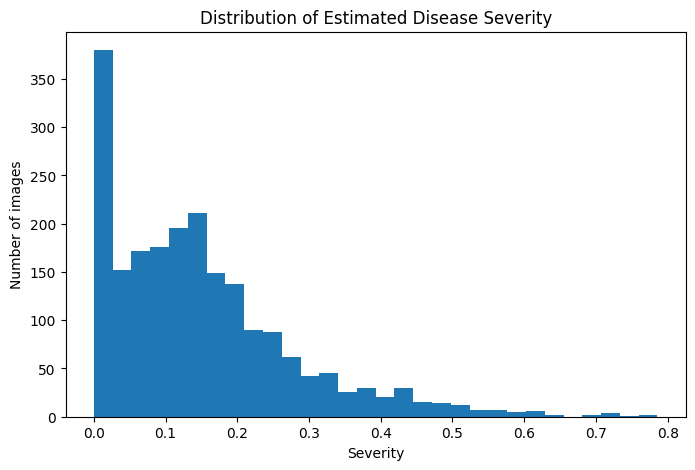

In [20]:
plt.figure(figsize=(8,5))

plt.hist(df["severity"], bins=30)

plt.xlabel("Severity")
plt.ylabel("Number of images")
plt.title("Distribution of Estimated Disease Severity")

plt.show()

In [21]:
from scipy.stats import spearmanr

corr, p = spearmanr(df["age"], df["severity"])

print(f"Spearman correlation = {corr:.4f}")
print(f"p-value = {p:.6g}")

Spearman correlation = 0.1978
p-value = 7.89345e-20


[ WARN:0@5760.028] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100066.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5760.073] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100094.jpg'): can't open/read file: check file path/integrity


Mask not found: 100066.jpg
Mask not found: 100094.jpg


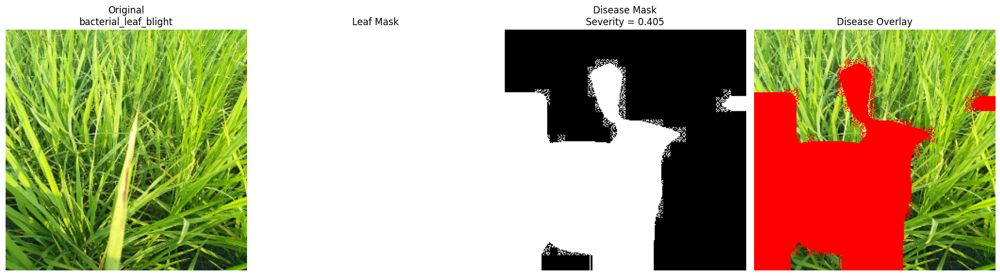

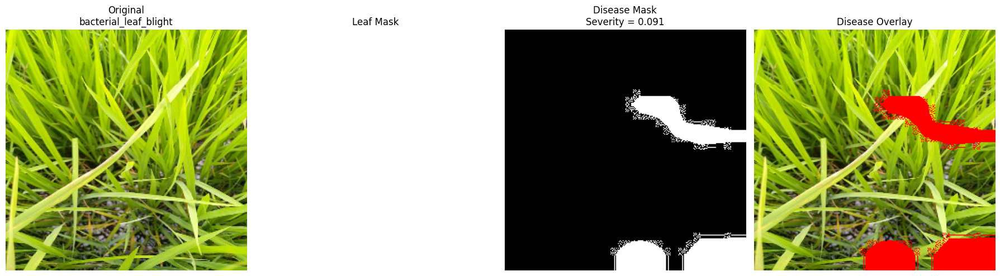

Mask not found: 100040.jpg
Mask not found: 100045.jpg
Mask not found: 100022.jpg
Mask not found: 100093.jpg
Mask not found: 100098.jpg
Mask not found: 100100.jpg


[ WARN:0@5763.715] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100040.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5763.755] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100045.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5763.789] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100022.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5763.821] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100093.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5763.835] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100098.jpg'): can't open/read file: check file path/integrity
[ WARN:0@5763.847] global loadsave.cpp:268 findDecoder imread_('/kaggle/working/masks/100100.jpg'): can't open/read file: check file path/integrity


In [22]:
# ============================================================
# VISUAL VALIDATION — CORRECTED MASK DISPLAY
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

classes_to_check = [
    "normal",
    "bacterial_leaf_blight",
    "blast",
    "brown_spot",
    "tungro"
]

samples_per_class = 2

for cls in classes_to_check:

    subset = df[df["true_label"] == cls].head(samples_per_class)

    for _, row in subset.iterrows():

        img_id = row["image_id"]
        severity = row["severity"]

        # ----------------------------------------------------
        # Find original image
        # ----------------------------------------------------

        original_path = None

        for root, dirs, files in os.walk(
            "/kaggle/input/paddy-disease-classification/train_images"
        ):
            if img_id in files:
                original_path = os.path.join(root, img_id)
                break

        if original_path is None:
            print("Could not find:", img_id)
            continue

        # ----------------------------------------------------
        # Read original
        # ----------------------------------------------------

        raw_bgr = cv2.imread(original_path)

        if raw_bgr is None:
            print("Could not read:", img_id)
            continue

        raw_bgr = cv2.resize(raw_bgr, (256, 256))
        raw = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)

        # ----------------------------------------------------
        # Leaf mask
        # ----------------------------------------------------

        leaf_mask = get_leaf_mask(raw_bgr)

        # ----------------------------------------------------
        # Disease mask
        # ----------------------------------------------------

        mask_path = f"/kaggle/working/masks/{img_id}"

        disease_mask = cv2.imread(
            mask_path,
            cv2.IMREAD_GRAYSCALE
        )

        if disease_mask is None:
            print("Mask not found:", img_id)
            continue

        disease_mask = disease_mask > 0

        # ----------------------------------------------------
        # DISPLAY
        # ----------------------------------------------------

        fig, ax = plt.subplots(1, 4, figsize=(18, 5))

        # Original
        ax[0].imshow(raw)
        ax[0].set_title(
            f"Original\n{cls}"
        )
        ax[0].axis("off")

        # Leaf mask — IMPORTANT: multiply by 255
        ax[1].imshow(
            leaf_mask * 255,
            cmap="gray",
            vmin=0,
            vmax=255
        )
        ax[1].set_title("Leaf Mask")
        ax[1].axis("off")

        # Disease mask
        ax[2].imshow(
            disease_mask * 255,
            cmap="gray",
            vmin=0,
            vmax=255
        )
        ax[2].set_title(
            f"Disease Mask\nSeverity = {severity:.3f}"
        )
        ax[2].axis("off")

        # Disease overlay
        overlay = raw.copy()

        overlay[disease_mask] = (
            255,
            0,
            0
        )

        ax[3].imshow(overlay)
        ax[3].set_title("Disease Overlay")
        ax[3].axis("off")

        plt.tight_layout()
        plt.show()

Found 14 cropped images

Processing: bacterial leaf blight.jpg


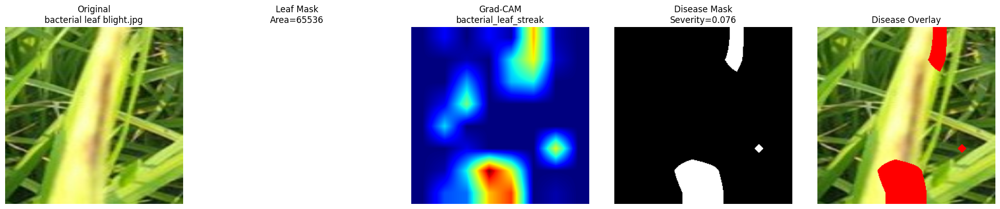

Prediction: bacterial_leaf_streak
Confidence: 0.4795
Leaf pixels: 65536
Disease pixels: 4960
Severity: 0.0757

Processing: bacterial leaf streak.jpg


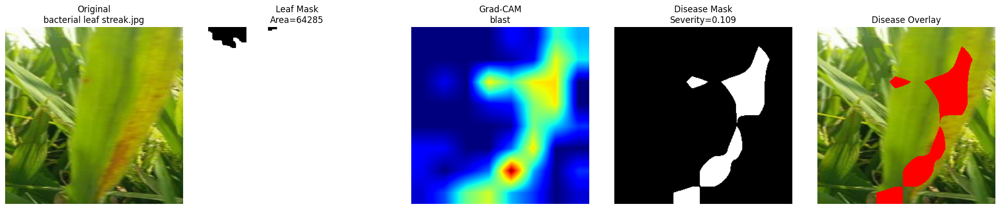

Prediction: blast
Confidence: 0.4326
Leaf pixels: 64285
Disease pixels: 6977
Severity: 0.1085

Processing: bacterial panicle blight.jpg


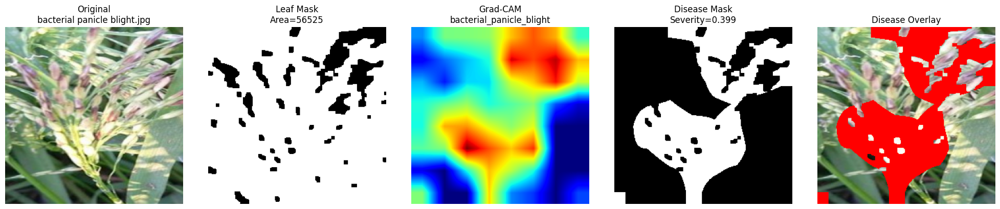

Prediction: bacterial_panicle_blight
Confidence: 0.9518
Leaf pixels: 56525
Disease pixels: 22570
Severity: 0.3993

Processing: blight.jpg


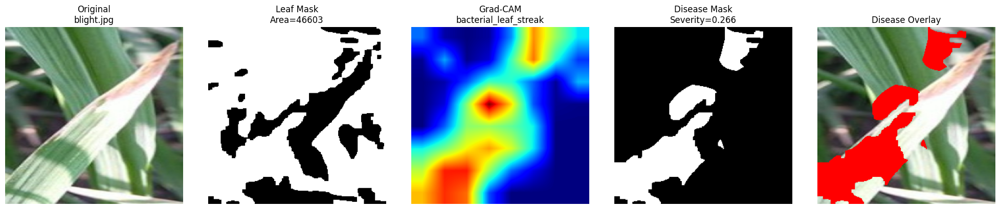

Prediction: bacterial_leaf_streak
Confidence: 0.4590
Leaf pixels: 46603
Disease pixels: 12410
Severity: 0.2663

Processing: blight2.jpg


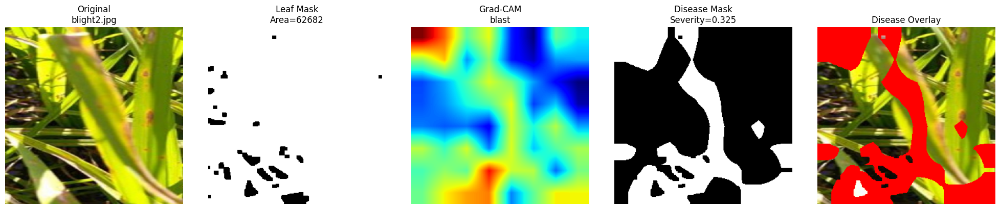

Prediction: blast
Confidence: 0.9503
Leaf pixels: 62682
Disease pixels: 20388
Severity: 0.3253

Processing: brown spot.jpg


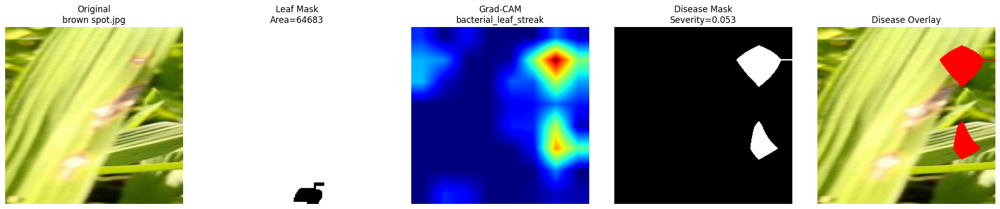

Prediction: bacterial_leaf_streak
Confidence: 0.5499
Leaf pixels: 64683
Disease pixels: 3423
Severity: 0.0529

Processing: dead heart.jpg


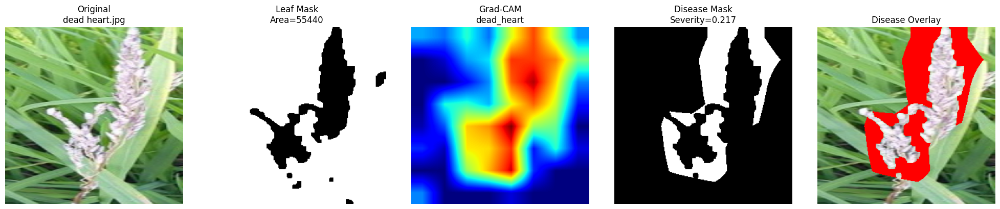

Prediction: dead_heart
Confidence: 0.9824
Leaf pixels: 55440
Disease pixels: 12045
Severity: 0.2173

Processing: dead heart2.jpg


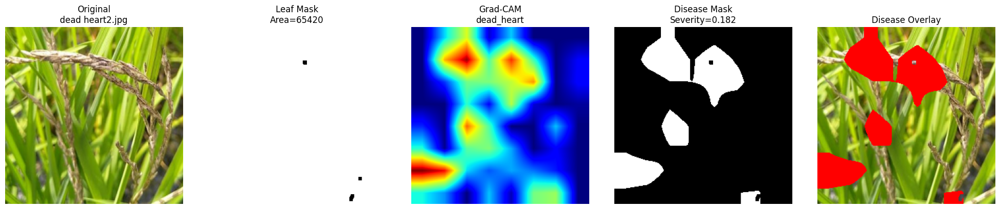

Prediction: dead_heart
Confidence: 0.6629
Leaf pixels: 65420
Disease pixels: 11933
Severity: 0.1824

Processing: downy mildew.jpg


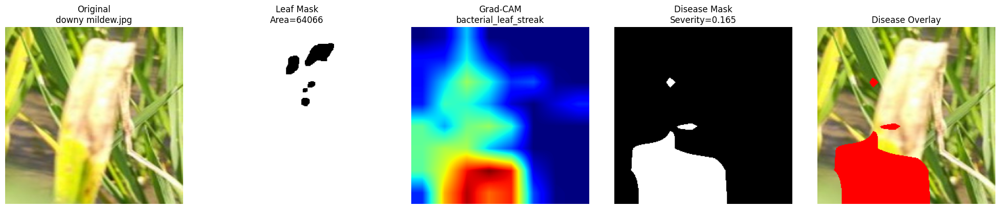

Prediction: bacterial_leaf_streak
Confidence: 0.5181
Leaf pixels: 64066
Disease pixels: 10570
Severity: 0.1650

Processing: hispa.jpg


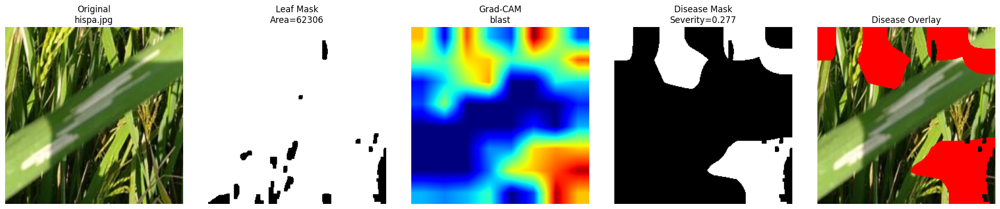

Prediction: blast
Confidence: 0.5062
Leaf pixels: 62306
Disease pixels: 17256
Severity: 0.2770

Processing: normal.jpg


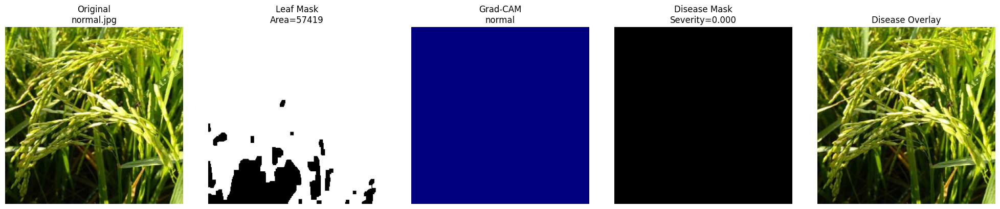

Prediction: normal
Confidence: 0.6018
Leaf pixels: 57419
Disease pixels: 0
Severity: 0.0000

Processing: normal1.jpg


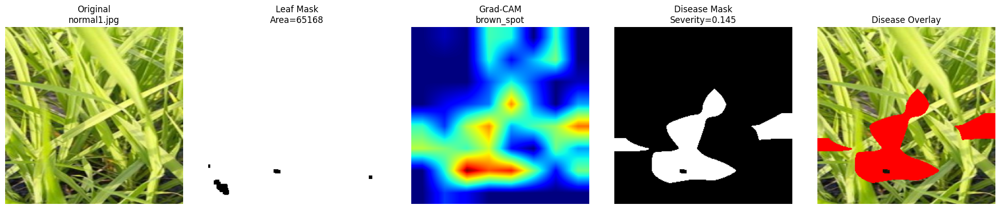

Prediction: brown_spot
Confidence: 0.4199
Leaf pixels: 65168
Disease pixels: 9460
Severity: 0.1452

Processing: normal2.jpg


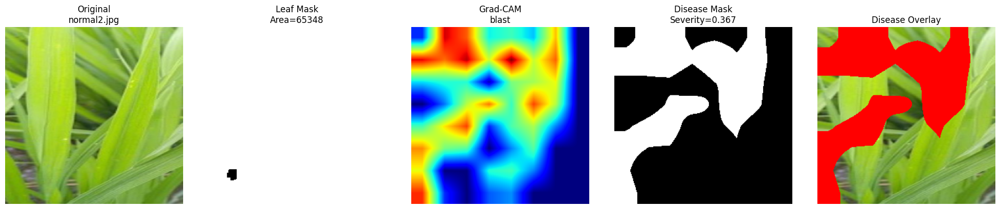

Prediction: blast
Confidence: 0.5738
Leaf pixels: 65348
Disease pixels: 23986
Severity: 0.3671

Processing: tungro2.jpg


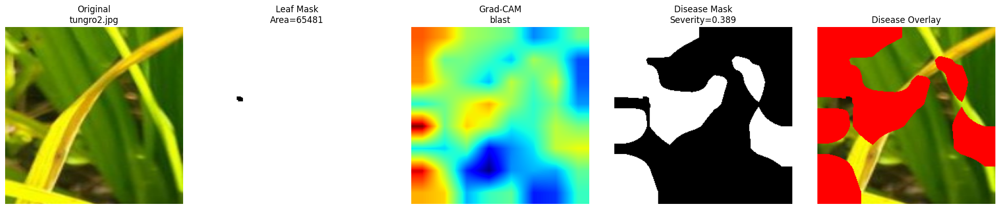

Prediction: blast
Confidence: 0.9446
Leaf pixels: 65481
Disease pixels: 25494
Severity: 0.3893


CROPPED IMAGE SEVERITY RESULTS
                        image_id                pred_label  confidence  \
0      bacterial leaf blight.jpg     bacterial_leaf_streak    0.479461   
1      bacterial leaf streak.jpg                     blast    0.432633   
2   bacterial panicle blight.jpg  bacterial_panicle_blight    0.951826   
3                     blight.jpg     bacterial_leaf_streak    0.459012   
4                    blight2.jpg                     blast    0.950342   
5                 brown spot.jpg     bacterial_leaf_streak    0.549917   
6                 dead heart.jpg                dead_heart    0.982364   
7                dead heart2.jpg                dead_heart    0.662869   
8               downy mildew.jpg     bacterial_leaf_streak    0.518136   
9                      hispa.jpg                     blast    0.506169   
10                    normal.jpg                    normal

In [23]:
# ============================================================
# SEVERITY TEST ON MANUALLY CROPPED IMAGES
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.applications.densenet import preprocess_input

# ------------------------------------------------------------
# 0. DEPENDENCY GUARD
#
# This cell reuses get_gradcam / grad_model / NORMAL_IDX / index_to_class
# from the severity-extraction cell rather than redefining them. That
# cell also contains the fix for the "normal leaves score highest
# severity" bug (contrastive Grad-CAM relative to NORMAL_IDX). If this
# cell is ever run standalone (fresh kernel, or after a restart) without
# rerunning that cell first, get_gradcam will either be undefined or
# -- worse -- silently be a stale, unfixed version from an earlier run.
# Fail loudly instead of producing quietly-wrong severity numbers.
# ------------------------------------------------------------

for _dep in ("get_gradcam", "grad_model", "NORMAL_IDX", "index_to_class", "model"):
    if _dep not in globals():
        raise RuntimeError(
            f"'{_dep}' is not defined. Rerun the severity-extraction "
            "pipeline cell (which defines get_gradcam with the "
            "contrastive/NORMAL_IDX fix) before running this cell."
        )

# ------------------------------------------------------------
# 1. SET PATH TO YOUR 12 MANUALLY CROPPED IMAGES
# ------------------------------------------------------------

CROP_DIR = "/kaggle/input/datasets/anayajain0101/cropped"

image_paths = []

for filename in sorted(os.listdir(CROP_DIR)):

    if filename.lower().endswith((".jpg", ".jpeg", ".png")):
        image_paths.append(
            os.path.join(CROP_DIR, filename)
        )

print(f"Found {len(image_paths)} cropped images")

if len(image_paths) == 0:
    raise ValueError(
        "No images found. Check CROP_DIR."
    )


# ------------------------------------------------------------
# 2. OUTPUT DIRECTORIES
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/cropped_severity"

MASK_DIR = os.path.join(
    OUTPUT_DIR,
    "disease_masks"
)

LEAF_DIR = os.path.join(
    OUTPUT_DIR,
    "leaf_masks"
)

OVERLAY_DIR = os.path.join(
    OUTPUT_DIR,
    "overlays"
)

os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(LEAF_DIR, exist_ok=True)
os.makedirs(OVERLAY_DIR, exist_ok=True)


# ------------------------------------------------------------
# 3. LEAF SEGMENTATION
# ------------------------------------------------------------

MORPH_KERNEL = np.ones((5, 5), np.uint8)


def get_leaf_mask(raw_bgr):

    hsv = cv2.cvtColor(
        raw_bgr,
        cv2.COLOR_BGR2HSV
    )

    # Green leaf range
    lower = np.array([10, 30, 30])
    upper = np.array([95, 255, 255])

    mask = cv2.inRange(
        hsv,
        lower,
        upper
    )

    # Clean small gaps/noise
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        MORPH_KERNEL
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        MORPH_KERNEL
    )

    # --------------------------------------------------------
    # Keep largest connected green region
    # Appropriate here because these are manually cropped
    # around ONE target leaf.
    # --------------------------------------------------------

    num_labels, labels, stats, _ = \
        cv2.connectedComponentsWithStats(mask)

    if num_labels > 1:

        largest = 1 + np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
        )

        mask = (
            labels == largest
        ).astype(np.uint8)

    else:

        mask = (
            mask > 0
        ).astype(np.uint8)

    return mask


# ------------------------------------------------------------
# 4. SEVERITY PARAMETERS
# ------------------------------------------------------------

ABS_ACTIVATION_THRESHOLD = 0.5

MIN_COMPONENT_FRACTION = 0.001


# ------------------------------------------------------------
# 5. PROCESS IMAGES
# ------------------------------------------------------------

records = []


for image_path in image_paths:

    filename = os.path.basename(image_path)

    print("\nProcessing:", filename)

    # --------------------------------------------------------
    # READ ORIGINAL
    # --------------------------------------------------------

    raw_bgr = cv2.imread(image_path)

    if raw_bgr is None:

        print(
            "Could not read:",
            filename
        )

        continue

    raw_bgr = cv2.resize(
        raw_bgr,
        (256, 256)
    )

    raw_rgb = cv2.cvtColor(
        raw_bgr,
        cv2.COLOR_BGR2RGB
    )


    # --------------------------------------------------------
    # MODEL INPUT
    # --------------------------------------------------------

    model_input = raw_rgb.astype(
        np.float32
    )

    model_input = preprocess_input(
        model_input
    )

    model_input = np.expand_dims(
        model_input,
        axis=0
    )


    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    prediction = model.predict(
        model_input,
        verbose=0
    )

    pred_idx = int(
        np.argmax(prediction[0])
    )

    pred_confidence = float(
        prediction[0][pred_idx]
    )


    # --------------------------------------------------------
    # CLASS NAME
    #
    # Reuses the shared index_to_class (built from val_ds.class_indices
    # in the severity-extraction cell) instead of a separate hardcoded
    # dict, so this stays correct even if class folders are ever added,
    # removed, or renamed.
    # --------------------------------------------------------

    pred_label = index_to_class.get(
        pred_idx,
        str(pred_idx)
    )


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    heatmap = get_gradcam(
        model_input,
        pred_idx
    )

    # get_gradcam already applies ReLU + max-normalization internally
    # (and returns an all-zero heatmap when the prediction is "normal",
    # per the contrastive fix), so no further normalization is needed
    # here.
    heatmap = cv2.resize(
        heatmap,
        (256, 256)
    )


    # --------------------------------------------------------
    # LEAF MASK
    # --------------------------------------------------------

    leaf_mask = get_leaf_mask(
        raw_bgr
    )

    leaf_area = int(
        leaf_mask.sum()
    )

    if leaf_area == 0:

        print(
            "WARNING: leaf mask is empty"
        )

        continue


    # --------------------------------------------------------
    # GRAD-CAM ACTIVATION MASK
    # --------------------------------------------------------

    activation_mask = (
        heatmap >= ABS_ACTIVATION_THRESHOLD
    ).astype(np.uint8)


    # --------------------------------------------------------
    # RESTRICT ACTIVATION TO LEAF
    # --------------------------------------------------------

    diseased_candidate = (
        activation_mask &
        leaf_mask
    ).astype(np.uint8)


    # --------------------------------------------------------
    # CONNECTED COMPONENTS
    # --------------------------------------------------------

    num_labels, labels, stats, _ = \
        cv2.connectedComponentsWithStats(
            diseased_candidate
        )


    min_area = max(
        5,
        int(
            MIN_COMPONENT_FRACTION *
            leaf_area
        )
    )


    final_mask = np.zeros_like(
        diseased_candidate
    )


    for lbl in range(
        1,
        num_labels
    ):

        component_area = stats[
            lbl,
            cv2.CC_STAT_AREA
        ]

        if component_area >= min_area:

            final_mask[
                labels == lbl
            ] = 1


    # --------------------------------------------------------
    # SEVERITY
    # --------------------------------------------------------

    diseased_area = int(
        final_mask.sum()
    )

    severity = (
        diseased_area /
        leaf_area
    )


    # --------------------------------------------------------
    # SAVE MASKS
    # --------------------------------------------------------

    cv2.imwrite(
        os.path.join(
            LEAF_DIR,
            filename
        ),
        leaf_mask * 255
    )

    cv2.imwrite(
        os.path.join(
            MASK_DIR,
            filename
        ),
        final_mask * 255
    )


    # --------------------------------------------------------
    # CREATE OVERLAY
    # --------------------------------------------------------

    overlay = raw_rgb.copy()

    overlay[final_mask == 1] = (
        255,
        0,
        0
    )

    cv2.imwrite(
        os.path.join(
            OVERLAY_DIR,
            filename
        ),
        cv2.cvtColor(
            overlay,
            cv2.COLOR_RGB2BGR
        )
    )


    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    records.append([
        filename,
        pred_label,
        pred_confidence,
        leaf_area,
        diseased_area,
        severity
    ])


    # --------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        1,
        5,
        figsize=(20, 4)
    )

    # Original
    ax[0].imshow(raw_rgb)
    ax[0].set_title(
        f"Original\n{filename}"
    )
    ax[0].axis("off")


    # Leaf mask
    ax[1].imshow(
        leaf_mask * 255,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax[1].set_title(
        f"Leaf Mask\nArea={leaf_area}"
    )

    ax[1].axis("off")


    # Grad-CAM
    ax[2].imshow(
        heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )

    ax[2].set_title(
        f"Grad-CAM\n{pred_label}"
    )

    ax[2].axis("off")


    # Final disease mask
    ax[3].imshow(
        final_mask * 255,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    ax[3].set_title(
        f"Disease Mask\nSeverity={severity:.3f}"
    )

    ax[3].axis("off")


    # Overlay
    ax[4].imshow(
        overlay
    )

    ax[4].set_title(
        "Disease Overlay"
    )

    ax[4].axis("off")


    plt.tight_layout()
    plt.show()


    print(
        f"Prediction: {pred_label}"
    )

    print(
        f"Confidence: {pred_confidence:.4f}"
    )

    print(
        f"Leaf pixels: {leaf_area}"
    )

    print(
        f"Disease pixels: {diseased_area}"
    )

    print(
        f"Severity: {severity:.4f}"
    )


# ------------------------------------------------------------
# 6. RESULTS TABLE
# ------------------------------------------------------------

cropped_results = pd.DataFrame(
    records,
    columns=[
        "image_id",
        "pred_label",
        "confidence",
        "leaf_area",
        "diseased_area",
        "severity"
    ]
)


print("\n")
print("=" * 70)
print("CROPPED IMAGE SEVERITY RESULTS")
print("=" * 70)

print(
    cropped_results
)


# ------------------------------------------------------------
# 7. SUMMARY
# ------------------------------------------------------------

if len(cropped_results) > 0:

    print("\nSeverity statistics:")

    print(
        cropped_results[
            "severity"
        ].describe()
    )


# ------------------------------------------------------------
# 8. SAVE CSV
# ------------------------------------------------------------

cropped_results.to_csv(
    "/kaggle/working/cropped_severity_results.csv",
    index=False
)

print(
    "\nSaved:"
)

print(
    "/kaggle/working/cropped_severity_results.csv"
)

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

mask_dir = "/kaggle/working/masks"

mask_files = sorted(os.listdir(mask_dir))

print("Masks saved:", len(mask_files))
print(mask_files[:10])

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

mask_dir = "/kaggle/working/masks"

mask_files = sorted(os.listdir(mask_dir))

print("Masks saved:", len(mask_files))
print(mask_files[:10])

In [26]:
from glob import glob

print(glob("/kaggle/input/datasets/anayajain0101/cropped/*"))

['/kaggle/input/datasets/anayajain0101/cropped/blight2.jpg', '/kaggle/input/datasets/anayajain0101/cropped/bacterial leaf streak.jpg', '/kaggle/input/datasets/anayajain0101/cropped/bacterial panicle blight.jpg', '/kaggle/input/datasets/anayajain0101/cropped/tungro2.jpg', '/kaggle/input/datasets/anayajain0101/cropped/hispa.jpg', '/kaggle/input/datasets/anayajain0101/cropped/blight.jpg', '/kaggle/input/datasets/anayajain0101/cropped/normal2.jpg', '/kaggle/input/datasets/anayajain0101/cropped/brown spot.jpg', '/kaggle/input/datasets/anayajain0101/cropped/normal1.jpg', '/kaggle/input/datasets/anayajain0101/cropped/dead heart.jpg', '/kaggle/input/datasets/anayajain0101/cropped/dead heart2.jpg', '/kaggle/input/datasets/anayajain0101/cropped/bacterial leaf blight.jpg', '/kaggle/input/datasets/anayajain0101/cropped/downy mildew.jpg', '/kaggle/input/datasets/anayajain0101/cropped/normal.jpg']


In [27]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/anayajain0101/cropped"):
    print(root)
    print(files[:5])   # prints first few files

/kaggle/input/datasets/anayajain0101/cropped
['blight2.jpg', 'bacterial leaf streak.jpg', 'bacterial panicle blight.jpg', 'tungro2.jpg', 'hispa.jpg']


Number of images: 14
['/kaggle/input/datasets/anayajain0101/cropped/bacterial leaf blight.jpg', '/kaggle/input/datasets/anayajain0101/cropped/bacterial leaf streak.jpg', '/kaggle/input/datasets/anayajain0101/cropped/bacterial panicle blight.jpg', '/kaggle/input/datasets/anayajain0101/cropped/blight.jpg', '/kaggle/input/datasets/anayajain0101/cropped/blight2.jpg', '/kaggle/input/datasets/anayajain0101/cropped/brown spot.jpg', '/kaggle/input/datasets/anayajain0101/cropped/dead heart.jpg', '/kaggle/input/datasets/anayajain0101/cropped/dead heart2.jpg', '/kaggle/input/datasets/anayajain0101/cropped/downy mildew.jpg', '/kaggle/input/datasets/anayajain0101/cropped/hispa.jpg', '/kaggle/input/datasets/anayajain0101/cropped/normal.jpg', '/kaggle/input/datasets/anayajain0101/cropped/normal1.jpg', '/kaggle/input/datasets/anayajain0101/cropped/normal2.jpg', '/kaggle/input/datasets/anayajain0101/cropped/tungro2.jpg']


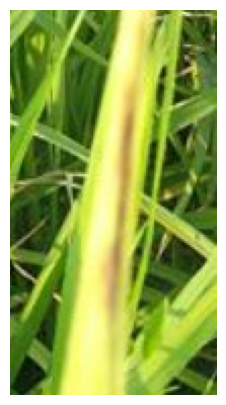

In [28]:
from glob import glob
import cv2
import matplotlib.pyplot as plt

image_paths = sorted(
    glob("/kaggle/input/datasets/anayajain0101/cropped/*.jpg")
)

print("Number of images:", len(image_paths))
print(image_paths)

img = cv2.imread(image_paths[0])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5,5))
plt.imshow(img)
plt.axis("off")
plt.show()

In [24]:
# ================================
# JEI ANALYSIS + PLOTS CELL
# ================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ---------------------------------------
# 1. LOAD SEVERITY CSV
# ---------------------------------------
csv_path = "/kaggle/working/severity_scores.csv"
assert os.path.exists(csv_path), "CSV not found! Did you run severity extraction?"
df = pd.read_csv(csv_path)

df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['severity'] = pd.to_numeric(df['severity'], errors='coerce')
df = df.dropna(subset=['age','severity'])

print("Rows:", len(df))
print(df.head())

# ---------------------------------------
# 2. SUMMARY STATISTICS
# ---------------------------------------
print("\n=== SUMMARY ===")
print(df[['age','severity']].describe())

print("\nAge range:", df['age'].min(), "-", df['age'].max())
print("Severity range:", df['severity'].min(), "-", df['severity'].max())

# ---------------------------------------
# 3. CORRELATIONS (JEI-SAFE)
# ---------------------------------------
pearson_r, pearson_p = stats.pearsonr(df['age'], df['severity'])
spearman_r, spearman_p = stats.spearmanr(df['age'], df['severity'])

print(f"\nPearson r = {pearson_r:.4f}, p = {pearson_p:.4g}")
print(f"Spearman rho = {spearman_r:.4f}, p = {spearman_p:.4g}")

# ---------------------------------------
# 4. SIMPLE LINEAR REGRESSION
# ---------------------------------------
slope, intercept, r_val, p_val, std_err = stats.linregress(df['age'], df['severity'])
print(f"\nLinear regression: severity = {slope:.6f}*age + {intercept:.6f}")
print(f"R² = {r_val**2:.4f}, p = {p_val:.4g}")

# ---------------------------------------
# 5. KRUSKAL–WALLIS (JEI-friendly ANOVA)
# ---------------------------------------
groups = [grp['severity'].values for name, grp in df.groupby('true_label')]
kw_stat, kw_p = stats.kruskal(*groups)
print(f"\nKruskal–Wallis H = {kw_stat:.4f}, p = {kw_p:.4g}")

# ---------------------------------------
# 6. AGE BINS
# ---------------------------------------
bins = [0,20,40,60,80,200]
labels = ['0–20','21–40','41–60','61–80','81+']
df['age_bin'] = pd.cut(df['age'], bins=bins, labels=labels, include_lowest=True)

print("\nSeverity by age bin:")
print(df.groupby('age_bin').severity.agg(['count','mean','median','std']))

# ---------------------------------------
# 7. PLOT DIRECTORY
# ---------------------------------------
out_dir = "/kaggle/working/jei_plots"
os.makedirs(out_dir, exist_ok=True)

# ---------------------------------------
# 8. FIGURE 1: Age vs Severity (scatter + line)
# ---------------------------------------
plt.figure(figsize=(6,5))
plt.scatter(df['age'], df['severity'], alpha=0.35)
x = np.linspace(df['age'].min(), df['age'].max(), 300)
y = intercept + slope*x
plt.plot(x, y)
plt.xlabel("Plant Age (days)")
plt.ylabel("Severity (fraction of leaf area)")
plt.title("Age vs Severity (scatter + trendline)")
plt.tight_layout()
plt.savefig(f"{out_dir}/figure_age_vs_severity.png", dpi=150)
plt.close()

# ---------------------------------------
# 9. FIGURE 2: Severity by disease (top diseases)
# ---------------------------------------
counts = df['true_label'].value_counts()
diseases = counts[counts >= 20].index.tolist()  # only stable categories

if len(diseases) > 0:
    data = [df[df['true_label']==d]['severity'].values for d in diseases]
    plt.figure(figsize=(10,4))
    plt.boxplot(data, labels=diseases, vert=True, showfliers=False)
    plt.xticks(rotation=60)
    plt.ylabel("Severity")
    plt.title("Severity distribution across disease types")
    plt.tight_layout()
    plt.savefig(f"{out_dir}/figure_severity_by_disease.png", dpi=150)
    plt.close()

# ---------------------------------------
# 10. FIGURE 3: Mean severity per disease
# ---------------------------------------
mean_sev = df.groupby('true_label').severity.mean().sort_values(ascending=False)
plt.figure(figsize=(9,4))
plt.bar(mean_sev.index, mean_sev.values)
plt.xticks(rotation=60)
plt.ylabel("Mean Severity")
plt.title("Mean severity per disease type")
plt.tight_layout()
plt.savefig(f"{out_dir}/figure_mean_severity.png", dpi=150)
plt.close()

# ---------------------------------------
# 11. FIGURE 4: Age-bin severity
# ---------------------------------------
agebin_stats = df.groupby('age_bin').severity.mean()
plt.figure(figsize=(6,4))
plt.bar(agebin_stats.index.astype(str), agebin_stats.values)
plt.xlabel("Age Bin (days)")
plt.ylabel("Mean Severity")
plt.title("Severity vs Plant Age Group")
plt.tight_layout()
plt.savefig(f"{out_dir}/figure_agebin_severity.png", dpi=150)
plt.close()

print("\nAll plots saved in:", out_dir)
print("Done!")


Rows: 2084
     image_id  age             true_label             pred_label  severity
0  100169.jpg   65  bacterial_leaf_blight  bacterial_leaf_blight  0.404694
1  100365.jpg   45  bacterial_leaf_blight                  blast  0.091476
2  100382.jpg   45  bacterial_leaf_blight  bacterial_leaf_blight  0.389856
3  100513.jpg   65  bacterial_leaf_blight  bacterial_leaf_blight  0.404694
4  100632.jpg   45  bacterial_leaf_blight  bacterial_leaf_blight  0.213669

=== SUMMARY ===
               age     severity
count  2084.000000  2084.000000
mean     63.750000     0.148817
std       9.083037     0.131399
min      45.000000     0.000000
25%      57.000000     0.050172
50%      67.000000     0.127126
75%      70.000000     0.207215
max      82.000000     0.785825

Age range: 45 - 82
Severity range: 0.0 - 0.7858252175882486

Pearson r = 0.1329, p = 1.121e-09
Spearman rho = 0.1978, p = 7.893e-20

Linear regression: severity = 0.001923*age + 0.026236
R² = 0.0177, p = 1.121e-09

Kruskal–Wallis H =

/tmp/ipykernel_40/1468399645.py:65: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('age_bin').severity.agg(['count','mean','median','std']))
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()



All plots saved in: /kaggle/working/jei_plots
Done!


/tmp/ipykernel_40/1468399645.py:121: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agebin_stats = df.groupby('age_bin').severity.mean()


In [16]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    for f in files:
        print("   ", f)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/anayajain0101
/kaggle/input/datasets/anayajain0101/cropped
    blight2.jpg
    bacterial leaf streak.jpg
    bacterial panicle blight.jpg
    tungro2.jpg
    hispa.jpg
    blight.jpg
    normal2.jpg
    brown spot.jpg
    normal1.jpg
    dead heart.jpg
    dead heart2.jpg
    bacterial leaf blight.jpg
    downy mildew.jpg
    normal.jpg
/kaggle/input/paddy-disease-classification
    sample_submission.csv
    train.csv
/kaggle/input/paddy-disease-classification/train_images
/kaggle/input/paddy-disease-classification/train_images/tungro
    109629.jpg
    104765.jpg
    109706.jpg
    100098.jpg
    102734.jpg
    106433.jpg
    108930.jpg
    102019.jpg
    102416.jpg
    101046.jpg
    108310.jpg
    104026.jpg
    110365.jpg
    102484.jpg
    107136.jpg
    105430.jpg
    101813.jpg
    107089.jpg
    104555.jpg
    107860.jpg
    107042.jpg
    100886.jpg
    107034.jpg
    101585.jpg
    101337.jpg
    103696.jpg
    10509

In [25]:
model.save("/kaggle/working/densenet_bio_tool.h5")
print("Saved!")

Saved!


In [26]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.densenet import preprocess_input

gradcam_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

gradcam_ds = gradcam_gen.flow_from_directory(
    "/kaggle/working/val",
    target_size=(256,256),
    batch_size=1,
    class_mode="categorical",
    shuffle=False
)

Found 2084 images belonging to 10 classes.


In [30]:
class_names = list(gradcam_ds.class_indices.keys())

print(class_names)

['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']


In [32]:
wanted = [
    "normal",
    "brown_spot",
    "blast"
]

In [33]:
selected = {}

for i in range(len(gradcam_ds.filenames)):
    label = np.argmax(gradcam_ds[i][1][0])
    classname = class_names[label]

    if classname in wanted and classname not in selected:
        selected[classname] = i

    if len(selected) == len(wanted):
        break

print(selected)

{'blast': 240, 'brown_spot': 588, 'normal': 1513}


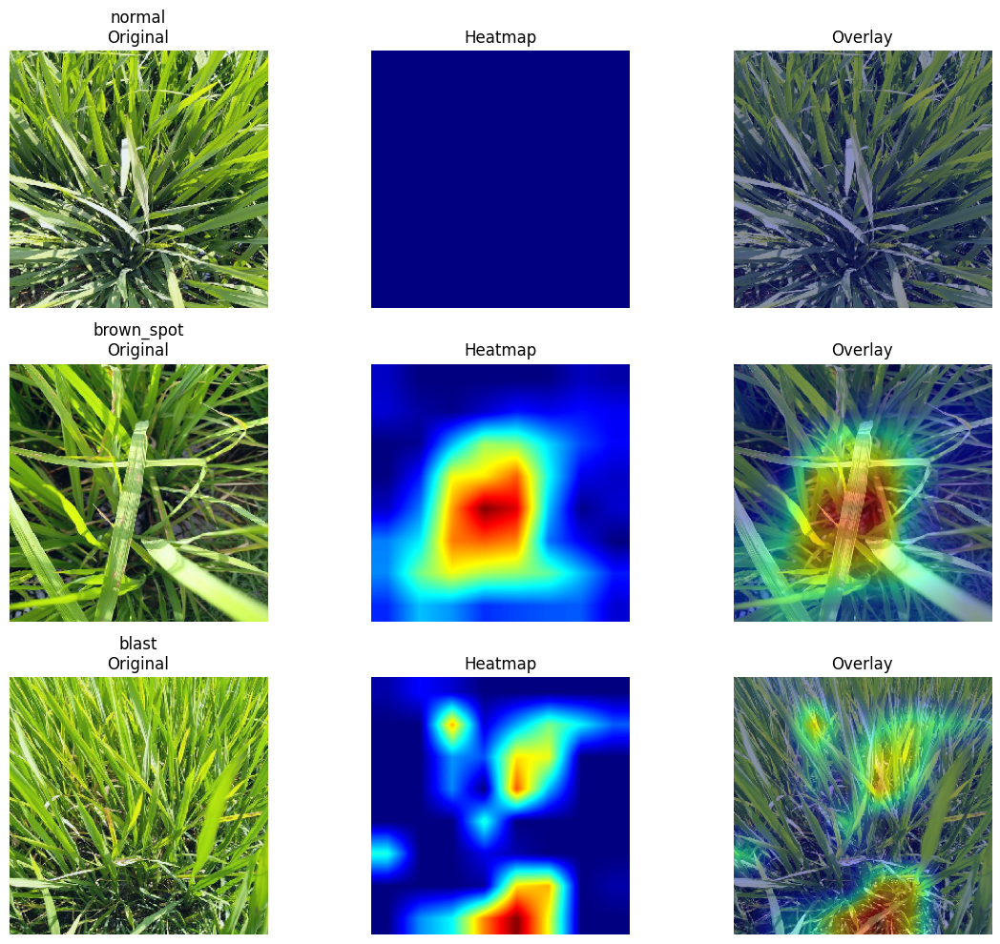

In [34]:
plt.figure(figsize=(12,10))

panel = 1

for disease in wanted:

    idx = selected[disease]

    img, label = gradcam_ds[idx]

    heatmap = get_gradcam(img)

    image = img[0]

    image = image - image.min()
    image = image/(image.max()+1e-8)
    image = (image*255).astype(np.uint8)

    hm = cv2.resize(heatmap,(256,256))
    hm = np.uint8(255*hm)
    hm = cv2.applyColorMap(hm,cv2.COLORMAP_JET)

    hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)

    overlay = cv2.addWeighted(image,0.6,hm,0.4,0)

    # Original
    plt.subplot(3,3,panel)
    plt.imshow(image)
    plt.title(f"{disease}\nOriginal")
    plt.axis("off")
    panel += 1

    # Heatmap
    plt.subplot(3,3,panel)
    plt.imshow(hm)
    plt.title("Heatmap")
    plt.axis("off")
    panel += 1

    # Overlay
    plt.subplot(3,3,panel)
    plt.imshow(overlay)
    plt.title("Overlay")
    plt.axis("off")
    panel += 1

plt.tight_layout()

plt.savefig("/kaggle/working/Figure3_GradCAM.png",dpi=300)

plt.show()

In [35]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 8, 8, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,125,472 (34.81 MB)

 Trainable params: 908,938 (3.47 MB)

 Non-trainable params: 6,398,656 (24.41 MB)

 Optimizer params: 1,817,878 (6.93 MB)

In [36]:
for layer in model.layers[0].layers[-20:]:
    print(layer.name, layer.output.shape)

conv5_block14_1_bn (None, 8, 8, 128)
conv5_block14_1_relu (None, 8, 8, 128)
conv5_block14_2_conv (None, 8, 8, 32)
conv5_block14_concat (None, 8, 8, 960)
conv5_block15_0_bn (None, 8, 8, 960)
conv5_block15_0_relu (None, 8, 8, 960)
conv5_block15_1_conv (None, 8, 8, 128)
conv5_block15_1_bn (None, 8, 8, 128)
conv5_block15_1_relu (None, 8, 8, 128)
conv5_block15_2_conv (None, 8, 8, 32)
conv5_block15_concat (None, 8, 8, 992)
conv5_block16_0_bn (None, 8, 8, 992)
conv5_block16_0_relu (None, 8, 8, 992)
conv5_block16_1_conv (None, 8, 8, 128)
conv5_block16_1_bn (None, 8, 8, 128)
conv5_block16_1_relu (None, 8, 8, 128)
conv5_block16_2_conv (None, 8, 8, 32)
conv5_block16_concat (None, 8, 8, 1024)
bn (None, 8, 8, 1024)
relu (None, 8, 8, 1024)


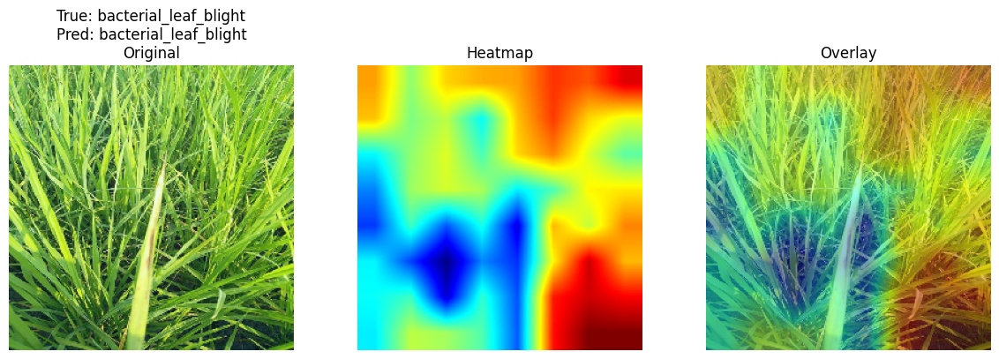

In [37]:
# ==========================================================
# GRAD-CAM (JEI FINAL VERSION)
# ==========================================================

import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

# -----------------------------
# Get model layers
# -----------------------------
backbone = model.layers[0]

gap_layer = model.layers[1]
bn1 = model.layers[2]
dense1 = model.layers[3]
bn2 = model.layers[4]
dense2 = model.layers[5]

# Last convolutional layer
last_conv_layer = backbone.get_layer("conv5_block16_concat")

# Model that outputs feature maps
grad_model = tf.keras.Model(
    inputs=backbone.input,
    outputs=[
        last_conv_layer.output,
        backbone.output
    ]
)

# ---------------------------------------------------------
# Grad-CAM
# ---------------------------------------------------------
def get_gradcam(img_array):

    with tf.GradientTape() as tape:

        conv_outputs, backbone_features = grad_model(img_array)

        x = gap_layer(backbone_features)
        x = bn1(x, training=False)
        x = dense1(x)
        x = bn2(x, training=False)
        predictions = dense2(x)

        pred_index = tf.argmax(predictions[0])
        class_score = predictions[:, pred_index]

    grads = tape.gradient(class_score, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap,0)
    heatmap = heatmap / (tf.reduce_max(heatmap)+1e-8)

    return heatmap.numpy(), pred_index.numpy()


# ---------------------------------------------------------
# Visualization
# ---------------------------------------------------------
def show_gradcam(img_array, heatmap, title):

    img = img_array[0].copy()

    img = img - img.min()
    img = img / (img.max()+1e-8)
    img = (img*255).astype(np.uint8)

    heatmap = cv2.resize(heatmap,(256,256))

    heatmap = np.uint8(255*heatmap)

    heatmap_color = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)


    overlay = cv2.addWeighted(
        img,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title(f"{title}\nOriginal")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(heatmap_color)
    plt.title("Heatmap")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(overlay)
    plt.title("Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------
# Generate Grad-CAM examples
# ---------------------------------------------------------

# Reset generator
val_ds.reset()

images, labels = next(val_ds)

for i in range(min(4, len(images))):

    img = np.expand_dims(images[i], axis=0)

    heatmap, pred = get_gradcam(img)

    true_label = class_names[np.argmax(labels[i])]
    pred_label = class_names[pred]

    show_gradcam(
        img,
        heatmap,
        f"True: {true_label}\nPred: {pred_label}"
    )

In [38]:
import os
print(os.listdir("/kaggle/working"))

['severity_scores.csv', 'cropped_severity', 'val', 'masks', 'densenet_bio_tool.keras', 'cropped_severity_results.csv', 'densenet_bio_tool.h5', 'Figure3_GradCAM.png', '.virtual_documents', 'jei_plots', 'train']


In [39]:
model.save("/kaggle/working/densenet_bio_tool.h5")
print("Model saved")

Model saved


In [40]:
df.to_csv("/kaggle/working/severity_scores.csv", index=False)
print("CSV saved")

CSV saved


In [47]:
import os
print(os.listdir("/kaggle/working/jei_plots"))

['figure_agebin_severity.png', 'figure_severity_by_disease.png', 'figure_age_vs_severity.png', 'figure_mean_severity.png']


2084/2084 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step


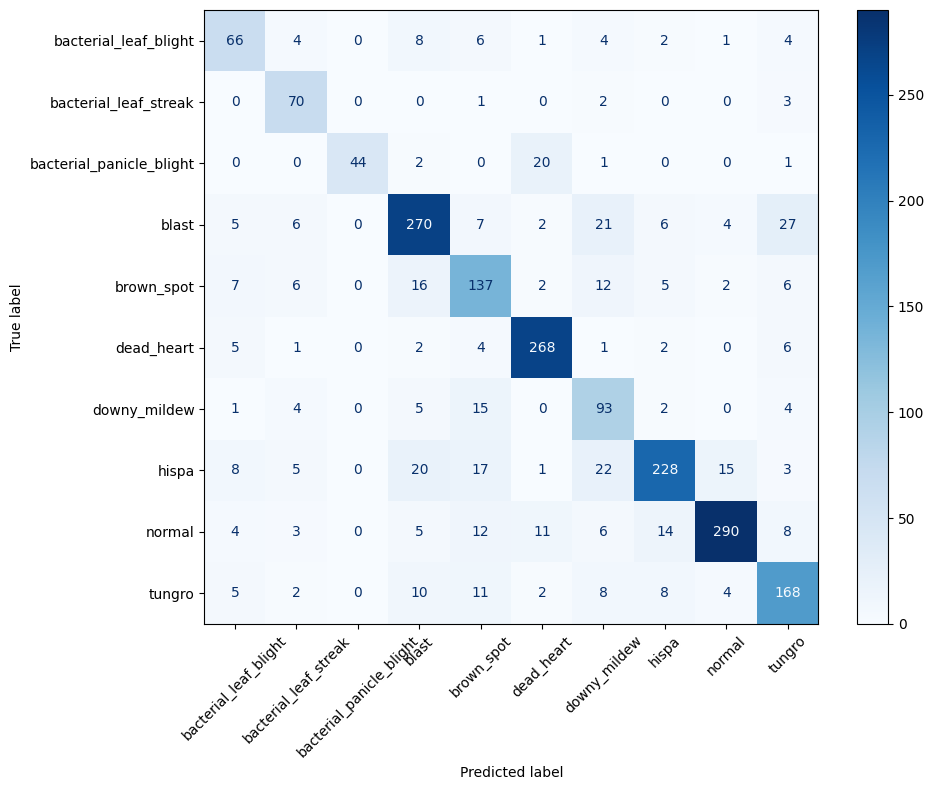

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# True labels
y_true = val_ds.classes

# Model predictions
y_pred_probs = model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Class names
class_names = list(val_ds.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d", ax=ax)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("/kaggle/working/confusion_matrix.png", dpi=300)
plt.show()

In [57]:
hispa_ds = val_gen.flow_from_directory(
    "/kaggle/working/val",
    target_size=(256, 256),
    classes=["hispa"],
    class_mode="categorical",
    shuffle=False,
    batch_size=1
)
y_pred_probs = model.predict(hispa_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)


Found 319 images belonging to 1 classes.
  4/319 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step 

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


319/319 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


In [50]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print("Classification Report:\n")
print(report)

Classification Report:

                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.65      0.69      0.67        96
   bacterial_leaf_streak       0.69      0.92      0.79        76
bacterial_panicle_blight       1.00      0.65      0.79        68
                   blast       0.80      0.78      0.79       348
              brown_spot       0.65      0.71      0.68       193
              dead_heart       0.87      0.93      0.90       289
            downy_mildew       0.55      0.75      0.63       124
                   hispa       0.85      0.71      0.78       319
                  normal       0.92      0.82      0.87       353
                  tungro       0.73      0.77      0.75       218

                accuracy                           0.78      2084
               macro avg       0.77      0.77      0.76      2084
            weighted avg       0.80      0.78      0.79      2084



In [51]:
import pandas as pd

report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
df_report = pd.DataFrame(report_dict).transpose()

df_report

,precision,recall,f1-score,support
bacterial_leaf_blight,0.653465,0.687500,0.670051,96.000000
bacterial_leaf_streak,0.693069,0.921053,0.790960,76.000000
bacterial_panicle_blight,1.000000,0.647059,0.785714,68.000000
blast,0.798817,0.775862,0.787172,348.000000
brown_spot,0.652381,0.709845,0.679901,193.000000
dead_heart,0.872964,0.927336,0.899329,289.000000
downy_mildew,0.547059,0.750000,0.632653,124.000000
hispa,0.853933,0.714734,0.778157,319.000000
normal,0.917722,0.821530,0.866966,353.000000
tungro,0.730435,0.770642,0.750000,218.000000


2084/2084 ━━━━━━━━━━━━━━━━━━━━ 22s 10ms/step


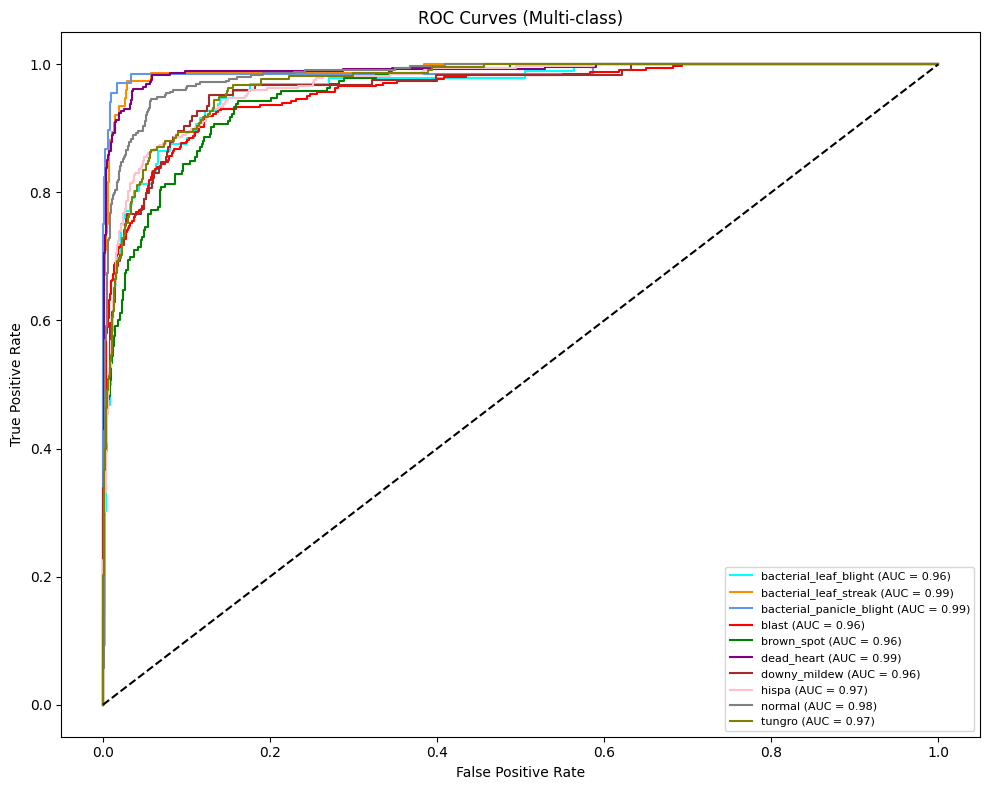

bacterial_leaf_blight: 0.9628
bacterial_leaf_streak: 0.9910
bacterial_panicle_blight: 0.9897
blast: 0.9573
brown_spot: 0.9567
dead_heart: 0.9905
downy_mildew: 0.9619
hispa: 0.9672
normal: 0.9835
tungro: 0.9691


In [52]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle
import matplotlib.pyplot as plt

# True labels
y_true = val_ds.classes

# Prediction probabilities
y_score = model.predict(val_ds, verbose=1)

# Number of classes
n_classes = len(class_names)

# Binarize labels
y_true_bin = label_binarize(y_true, classes=range(n_classes))

# Compute ROC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
plt.figure(figsize=(10,8))

colors = cycle([
    "aqua", "darkorange", "cornflowerblue", "red", "green",
    "purple", "brown", "pink", "gray", "olive"
])

for i, color in zip(range(n_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})"
    )

plt.plot([0,1], [0,1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (Multi-class)")
plt.legend(fontsize=8)
plt.tight_layout()

# Save BEFORE showing
plt.savefig("/kaggle/working/roc.png", dpi=300)
plt.show()

for i in range(n_classes):
    print(f"{class_names[i]}: {roc_auc[i]:.4f}")

In [53]:
model.save("/kaggle/working/densenet_bio_tool.h5")
print("Model saved")

Model saved


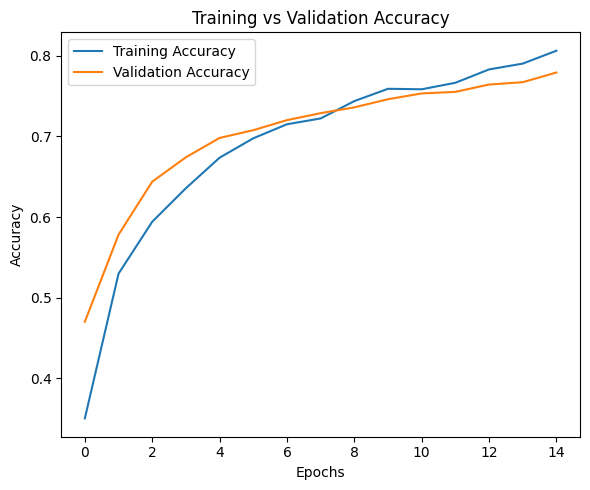

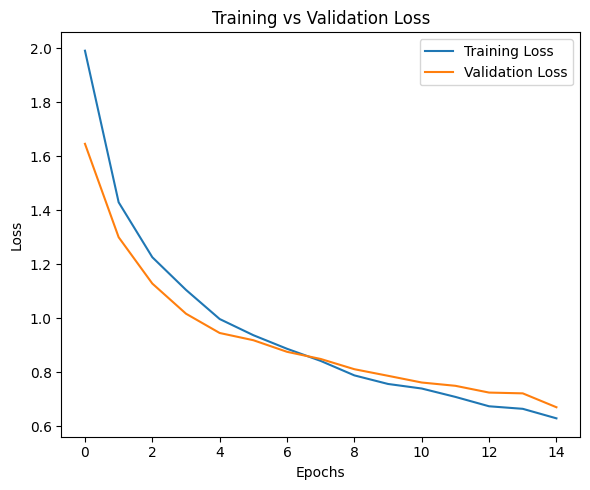

In [54]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(6,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/jei_plots/training_validation_accuracy.png", dpi=200)
plt.show()

# Loss
plt.figure(figsize=(6,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("/kaggle/working/jei_plots/training_validation_loss.png", dpi=200)
plt.show()



In [55]:
# Post-hoc Dunn test
!pip install scikit-posthocs

import scikit_posthocs as sp

dunn = sp.posthoc_dunn(
    df,
    val_col='severity',
    group_col='true_label',
    p_adjust='bonferroni'
)

dunn

,bacterial_leaf_blight,bacterial_leaf_streak,bacterial_panicle_blight,blast,brown_spot,dead_heart,downy_mildew,hispa,normal,tungro
bacterial_leaf_blight,1.000000e+00,2.477748e-01,1.876588e-04,1.000000e+00,7.235512e-01,1.000000e+00,3.813490e-02,9.365048e-11,5.452814e-57,1.284139e-05
bacterial_leaf_streak,2.477748e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.888663e-01,1.000000e+00,9.587442e-02,4.356498e-28,1.000000e+00
bacterial_panicle_blight,1.876588e-04,1.000000e+00,1.000000e+00,5.711024e-04,1.059662e-01,2.750293e-04,1.000000e+00,1.000000e+00,6.886769e-16,1.000000e+00
blast,1.000000e+00,1.000000e+00,5.711024e-04,1.000000e+00,1.000000e+00,1.000000e+00,1.700571e-01,3.247369e-16,1.656235e-111,1.410273e-06
brown_spot,7.235512e-01,1.000000e+00,1.059662e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,6.203414e-07,3.573351e-66,4.056586e-02
dead_heart,1.000000e+00,7.888663e-01,2.750293e-04,1.000000e+00,1.000000e+00,1.000000e+00,8.480238e-02,3.643654e-16,8.335773e-105,6.384496e-07
downy_mildew,3.813490e-02,1.000000e+00,1.000000e+00,1.700571e-01,1.000000e+00,8.480238e-02,1.000000e+00,2.565685e-02,1.243599e-39,1.000000e+00
hispa,9.365048e-11,9.587442e-02,1.000000e+00,3.247369e-16,6.203414e-07,3.643654e-16,2.565685e-02,1.000000e+00,1.113749e-39,1.000000e+00
normal,5.452814e-57,4.356498e-28,6.886769e-16,1.656235e-111,3.573351e-66,8.335773e-105,1.243599e-39,1.113749e-39,1.000000e+00,1.376396e-44
tungro,1.284139e-05,1.000000e+00,1.000000e+00,1.410273e-06,4.056586e-02,6.384496e-07,1.000000e+00,1.000000e+00,1.376396e-44,1.000000e+00


In [56]:
# =========================================
# LOAD DATA (IMPORTANT - fixes df error)
# =========================================
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

df = pd.read_csv("/kaggle/working/severity_scores.csv")

print("Data loaded:", df.shape)
df.head()


# =========================================
# 1. CLASSIFICATION REPORT (per disease)
# =========================================
y_true = df['true_label']
y_pred = df['pred_label']

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred))


# =========================================
# 2. CONFUSION MATRIX (optional but useful)
# =========================================
cm = confusion_matrix(y_true, y_pred)

print("\n=== CONFUSION MATRIX ===")
print(cm)


# =========================================
# 3. ACCURACY BY SEVERITY (VERY IMPORTANT)
# =========================================

# Low severity (<0.1)
low_sev = df[df['severity'] < 0.1]
acc_low = (low_sev['true_label'] == low_sev['pred_label']).mean()

# Medium severity (0.1–0.4)
mid_sev = df[(df['severity'] >= 0.1) & (df['severity'] < 0.4)]
acc_mid = (mid_sev['true_label'] == mid_sev['pred_label']).mean()

# High severity (>0.4)
high_sev = df[df['severity'] >= 0.4]
acc_high = (high_sev['true_label'] == high_sev['pred_label']).mean()

print("\n=== ACCURACY BY SEVERITY ===")
print(f"Low severity (<0.1): {acc_low:.2f}")
print(f"Medium severity (0.1–0.4): {acc_mid:.2f}")
print(f"High severity (>0.4): {acc_high:.2f}")


# =========================================
# 4. SAVE RESULTS (optional but good)
# =========================================
results = pd.DataFrame({
    "severity_range": ["<0.1", "0.1–0.4", ">0.4"],
    "accuracy": [acc_low, acc_mid, acc_high]
})

results.to_csv("/kaggle/working/jei_plots/accuracy_by_severity.csv", index=False)

print("\nSaved accuracy_by_severity.csv")

Data loaded: (2084, 6)

=== CLASSIFICATION REPORT ===
                          precision    recall  f1-score   support

   bacterial_leaf_blight       0.65      0.69      0.67        96
   bacterial_leaf_streak       0.69      0.92      0.79        76
bacterial_panicle_blight       1.00      0.65      0.79        68
                   blast       0.80      0.78      0.79       348
              brown_spot       0.65      0.71      0.68       193
              dead_heart       0.87      0.93      0.90       289
            downy_mildew       0.55      0.75      0.63       124
                   hispa       0.85      0.71      0.78       319
                  normal       0.92      0.82      0.87       353
                  tungro       0.73      0.77      0.75       218

                accuracy                           0.78      2084
               macro avg       0.77      0.77      0.76      2084
            weighted avg       0.80      0.78      0.79      2084


=== CONFUSION MATR

In [58]:
model.save("/kaggle/working/densenet_bio_tool.h5")
print("Model saved")

Model saved
